# TP4 Retail Intelligence

UC08 - analyses décisionnelles et visualisations. Les données réellement disponibles sont le Silver et le Gold issus de l'UC06.

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F
import matplotlib.pyplot as plt

spark = (SparkSession.builder.appName('TP4-Retail-Intelligence').master('local[2]').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('Version Spark :', spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 08:37:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Version Spark : 4.3.0


In [2]:
silver = spark.read.parquet('/opt/project/output/data/silver/promotion')
gold = spark.read.parquet('/opt/project/output/data/gold/promotion_summary')
print('Silver lignes :', silver.count())
print('Silver colonnes :', len(silver.columns))
print('Gold lignes :', gold.count())
silver.printSchema()

Silver lignes : 300
Silver colonnes : 19
Gold lignes : 9
root
 |-- field_00: integer (nullable = true)
 |-- field_01: string (nullable = true)
 |-- field_02: integer (nullable = true)
 |-- field_03: integer (nullable = true)
 |-- field_04: integer (nullable = true)
 |-- field_05: decimal(12,2) (nullable = true)
 |-- field_06: string (nullable = true)
 |-- field_07: string (nullable = true)
 |-- field_08: string (nullable = true)
 |-- field_09: string (nullable = true)
 |-- field_10: string (nullable = true)
 |-- field_11: string (nullable = true)
 |-- field_12: string (nullable = true)
 |-- field_13: string (nullable = true)
 |-- field_14: string (nullable = true)
 |-- field_15: string (nullable = true)
 |-- field_16: string (nullable = true)
 |-- field_17: string (nullable = true)
 |-- field_18: string (nullable = true)



## Statistiques descriptives

On calcule les statistiques avec Spark, puis on transfère uniquement le petit résultat vers Pandas.

In [3]:
stats = silver.select(F.count('*').alias('rows'), F.min('field_05').alias('min'), F.max('field_05').alias('max'), F.round(F.avg('field_05'), 2).alias('average'), F.expr('percentile_approx(field_05, 0.5)').alias('median')).toPandas()
stats

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

,rows,min,max,average,median
0,300,12.63,995.16,521.23,559.51


## Analyse 1 - catégories de promotion

Le Gold contient un agrégat par `field_07`, le champ technique réellement disponible.

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,field_07,promotion_count,average_cost
0,able,37,446.43
1,anti,36,564.18
2,ation,36,530.95
3,pri,35,577.82
4,bar,33,517.13
5,cally,33,545.79
6,ought,32,597.34
7,eing,31,514.89
8,ese,27,372.26


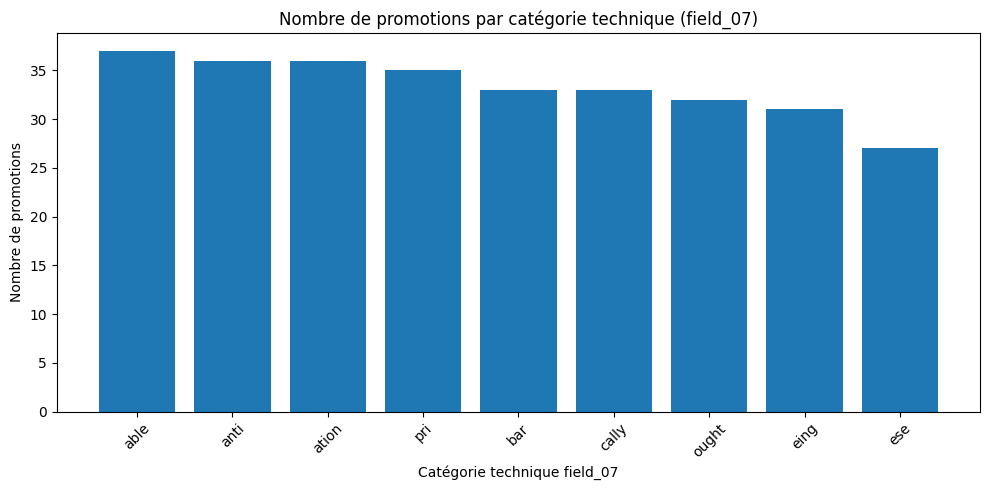

In [4]:
by_category = gold.orderBy(F.desc('promotion_count')).toPandas()
display(by_category)
plt.figure(figsize=(10, 5))
plt.bar(by_category['field_07'].astype(str), by_category['promotion_count'])
plt.title('Nombre de promotions par catégorie technique (field_07)')
plt.xlabel('Catégorie technique field_07')
plt.ylabel('Nombre de promotions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Analyse 2 - distribution de field_05

Cette distribution décrit les valeurs numériques observées ; l'unité métier reste à confirmer car la source n'a pas d'en-tête.

/opt/spark/python/pyspark/sql/pandas/conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


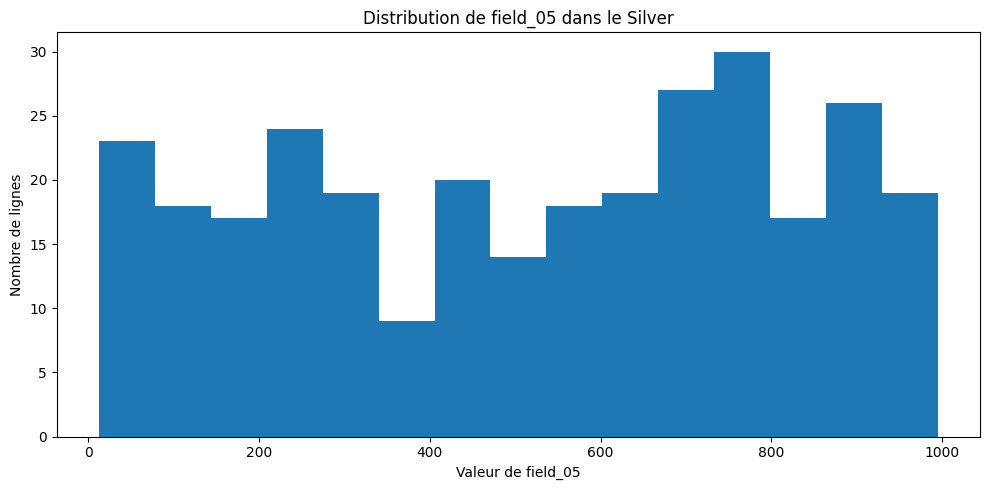

In [5]:
costs = silver.select('field_05').where(F.col('field_05').isNotNull()).toPandas()
plt.figure(figsize=(10, 5))
plt.hist(costs['field_05'], bins=15)
plt.title('Distribution de field_05 dans le Silver')
plt.xlabel('Valeur de field_05')
plt.ylabel('Nombre de lignes')
plt.tight_layout()
plt.show()

## Limites

L'extrait est synthétique, sans en-tête métier. Les champs sont donc documentés comme champs techniques et les conclusions restent descriptives.